# Nhận dạng cảm xúc bằng CNN + MLP (PyTorch)

Bản PyTorch của `Yêu cầu/examples/2. CNN + MLP/3_Emotion_Reg_CNN.ipynb`, giữ nguyên thứ tự mục và cấu hình của gốc.

- FER2013: ảnh mặt người xám 48×48, 7 cảm xúc (angry, disgust, fear, happy, sad, surprise, neutral).
- Mô hình: Conv64 same, Conv64 valid, Pool, Dropout 0.25; Conv128 same, Conv128 valid, Conv218 same, Conv218 valid, Pool, Dropout 0.25; FC 1024, Dropout 0.5; FC 7.
- Huấn luyện: `categorical_crossentropy`, Adam lr 1e-4, batch 128, 15 epoch; validation là PublicTest (gốc gọi là "testing").

| | Keras gốc (Keras 2.0.9, GTX 1080) | PyTorch |
|---|---|---|
| Số tham số | 19.028.287 | kiểm bằng `assert` ở mục (2) |
| Test accuracy | 0.5954 | xem mục (4) |
| Test loss | 1.4070 | xem mục (4) |
| Thời gian | 6,11 phút | xem mục (3) |

# Import libraries

Keras gốc:
```python
import keras
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import torch.nn.functional as F
import matplotlib.pyplot as plt

# True: chỉ chạy thử (ít dữ liệu, 1 epoch) để kiểm code trên CPU; bản nộp phải là False (chạy GPU)
CHAY_THU = False

set_seed(0)
device = get_device()

torch 2.11.0+cu130 | thiết bị: cuda (Tesla T4)


In [2]:
num_classes = 7   # angry, disgust, fear, happy, neutral, sad, and surprise
TEN = "3_Emotion_Reg_CNN"

# (1) Data

Keras gốc:
```python
trainingset = np.loadtxt('fer2013_training_onehot.csv', delimiter=',')
testingset = np.loadtxt('fer2013_publictest_onehot.csv', delimiter=',')
n_inputs = 2304
n_classes = 7
x_training = trainingset[:, 0:n_inputs]
y_training = trainingset[:, n_inputs:n_inputs + n_classes]
x_testing = testingset[:, 0:n_inputs]
y_testing = testingset[:, n_inputs:n_inputs + n_classes]
x_training = x_training.reshape(x_training.shape[0], 48, 48)
x_training = np.expand_dims(x_training, axis=4)
x_testing = x_testing.reshape(x_testing.shape[0], 48, 48)
x_testing = np.expand_dims(x_testing, axis=4)
```

Khác Keras:
- Hai file `*_onehot.csv` của gốc là `fer2013.csv` lọc theo cột `Usage` (Training, PublicTest) và đổi nhãn sang one-hot. `load_fer2013` trong `common.py` đọc thẳng `fer2013.csv` ra đúng các mảng đó; đã kiểm cùng số dòng và cùng thứ tự với output gốc.
- **Không chia 255** như gốc: ảnh vào mạng có giá trị 0–255.
- `(N, 48, 48, 1)` → `(N, 1, 48, 48)`; nhãn one-hot → chỉ số lớp.

In [3]:
x_training, y_training = load_fer2013("Training")     # (28709, 48, 48, 1), one-hot (28709, 7)
x_testing, y_testing = load_fer2013("PublicTest")     # (3589, 48, 48, 1)
print("gốc: Train on %d samples, validate on %d samples" % (len(x_training), len(x_testing)))

if CHAY_THU:
    x_training, y_training = x_training[:1000], y_training[:1000]
    x_testing, y_testing = x_testing[:300], y_testing[:300]

x_train, y_train = to_nchw(x_training), onehot_to_index(y_training)
x_test, y_test = to_nchw(x_testing), onehot_to_index(y_testing)
print(tuple(x_train.shape), tuple(x_test.shape), "| giá trị %.0f–%.0f" % (x_train.min(), x_train.max()))

gốc: Train on 28709 samples, validate on 3589 samples
(28709, 1, 48, 48) (3589, 1, 48, 48) | giá trị 0–255


# (2) Declare model

Keras gốc:
```python
input_image = Input(shape=(48, 48, 1), name='Input')
x = Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu', name='conv1_1')(input_image)
x = Conv2D(filters=64, kernel_size=(3, 3), padding='valid', activation='relu', name='conv1_2')(x)
x = MaxPooling2D(pool_size=(2, 2), name='pool1')(x)
x = Dropout(rate=0.25, name='conv_dropout1')(x)
x = Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu', name='conv2_1')(x)
x = Conv2D(filters=128, kernel_size=(3, 3), padding='valid', activation='relu', name='conv2_2')(x)
x = Conv2D(filters=218, kernel_size=(3, 3), padding='same', activation='relu', name='conv2_3')(x)
x = Conv2D(filters=218, kernel_size=(3, 3), padding='valid', activation='relu', name='conv2_4')(x)
x = MaxPooling2D(pool_size=(2, 2), name='pool2')(x)
x = Dropout(rate=0.25, name='conv_dropout2')(x)
x = Flatten(name='flatten')(x)
x = Dense(units=1024, activation='relu', name='fc1')(x)
x = Dropout(rate=0.5, name='fc_dropout1')(x)
output_label = Dense(units=num_classes, activation='softmax', name='fc3_7ways_softmax')(x)
model = Model(inputs=input_image, outputs=output_label, name='emo_cnn')
```

Khác Keras:
- `padding='same'` → `padding=1`, `padding='valid'` → `padding=0`. Gốc trộn cả hai nên kích thước: 48 → 48 → 46 → pool 23 → 23 → 21 → 21 → 19 → pool 9.
- Gốc dùng 218 filter (không phải 256), giữ nguyên. `Flatten` ra 218 × 9 × 9 = 17.658, nên `fc1` có 17.658 × 1024 + 1024 = 18.082.816 tham số (95% tổng số).
- Lớp cuối trả logits (softmax nằm trong `nn.CrossEntropyLoss`).

In [4]:
class EmoCNN(nn.Module):
    """emo_cnn: tên các lớp trùng `name=` Keras."""

    def __init__(self, num_classes=7):
        super().__init__()
        self.conv1_1 = nn.Conv2d(1, 64, 3, padding=1)      # same
        self.conv1_2 = nn.Conv2d(64, 64, 3, padding=0)     # valid
        self.pool1 = nn.MaxPool2d(2)
        self.conv_dropout1 = nn.Dropout(0.25)
        self.conv2_1 = nn.Conv2d(64, 128, 3, padding=1)    # same
        self.conv2_2 = nn.Conv2d(128, 128, 3, padding=0)   # valid
        self.conv2_3 = nn.Conv2d(128, 218, 3, padding=1)   # same
        self.conv2_4 = nn.Conv2d(218, 218, 3, padding=0)   # valid
        self.pool2 = nn.MaxPool2d(2)
        self.conv_dropout2 = nn.Dropout(0.25)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(218 * 9 * 9, 1024)
        self.fc_dropout1 = nn.Dropout(0.5)
        self.fc3_7ways_softmax = nn.Linear(1024, num_classes)   # trả logits

    def forward(self, x):                                  # (N, 1, 48, 48), giá trị 0–255
        x = F.relu(self.conv1_1(x))                        # (N, 64, 48, 48)
        x = F.relu(self.conv1_2(x))                        # (N, 64, 46, 46)
        x = self.conv_dropout1(self.pool1(x))              # (N, 64, 23, 23)
        x = F.relu(self.conv2_1(x))                        # (N, 128, 23, 23)
        x = F.relu(self.conv2_2(x))                        # (N, 128, 21, 21)
        x = F.relu(self.conv2_3(x))                        # (N, 218, 21, 21)
        x = F.relu(self.conv2_4(x))                        # (N, 218, 19, 19)
        x = self.conv_dropout2(self.pool2(x))              # (N, 218, 9, 9)
        x = self.flatten(x)                                # (N, 17658)
        x = self.fc_dropout1(F.relu(self.fc1(x)))          # (N, 1024)
        return self.fc3_7ways_softmax(x)                   # (N, 7)


model = init_keras_like(EmoCNN(num_classes)).to(device)
summary(model, input_size=(1, 1, 48, 48))

Layer (type:depth-idx)                   Output Shape              Param #
EmoCNN                                   [1, 7]                    --
├─Conv2d: 1-1                            [1, 64, 48, 48]           640
├─Conv2d: 1-2                            [1, 64, 46, 46]           36,928
├─MaxPool2d: 1-3                         [1, 64, 23, 23]           --
├─Dropout: 1-4                           [1, 64, 23, 23]           --
├─Conv2d: 1-5                            [1, 128, 23, 23]          73,856
├─Conv2d: 1-6                            [1, 128, 21, 21]          147,584
├─Conv2d: 1-7                            [1, 218, 21, 21]          251,354
├─Conv2d: 1-8                            [1, 218, 19, 19]          427,934
├─MaxPool2d: 1-9                         [1, 218, 9, 9]            --
├─Dropout: 1-10                          [1, 218, 9, 9]            --
├─Flatten: 1-11                          [1, 17658]                --
├─Linear: 1-12                           [1, 1024]           

In [5]:
# Số tham số phải trùng "Total params: 19,028,287" của model.summary() Keras
n_params = count_params(model)
print("Số tham số PyTorch:", n_params)
assert n_params == 19_028_287

Số tham số PyTorch: 19028287


# (3) Train defined model

Keras gốc:
```python
loss = 'categorical_crossentropy'
lr = 0.0001
model.compile(loss=loss, optimizer=Adam(lr=lr), metrics=['accuracy'])
batch_size = 128
epochs = 15
history = model.fit(x_training, y_training, validation_data=(x_testing, y_testing),
                    batch_size=batch_size, epochs=epochs)
```

In [6]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.0001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)   # betas, eps mặc định giống Keras 2.0.9

batch_size = 128
epochs = 1 if CHAY_THU else 15

train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs, metric=accuracy)
train_time = time.time() - starting_time
print('> training time is %.4f minutes' % (train_time / 60))

fit: train trên cuda (Tesla T4)
Epoch 1/15 - 23.0s - loss: 2.2129 - acc: 0.2359 - val_loss: 1.7996 - val_acc: 0.3132
Epoch 2/15 - 24.6s - loss: 1.7187 - acc: 0.3170 - val_loss: 1.6054 - val_acc: 0.3856
Epoch 3/15 - 23.7s - loss: 1.5962 - acc: 0.3829 - val_loss: 1.4947 - val_acc: 0.4274
Epoch 4/15 - 23.0s - loss: 1.5030 - acc: 0.4239 - val_loss: 1.4070 - val_acc: 0.4712
Epoch 5/15 - 23.5s - loss: 1.4054 - acc: 0.4629 - val_loss: 1.3376 - val_acc: 0.4946
Epoch 6/15 - 23.8s - loss: 1.3124 - acc: 0.5037 - val_loss: 1.2780 - val_acc: 0.5194
Epoch 7/15 - 23.6s - loss: 1.2241 - acc: 0.5392 - val_loss: 1.2583 - val_acc: 0.5366
Epoch 8/15 - 23.5s - loss: 1.1385 - acc: 0.5734 - val_loss: 1.2213 - val_acc: 0.5464
Epoch 9/15 - 23.7s - loss: 1.0387 - acc: 0.6124 - val_loss: 1.1736 - val_acc: 0.5678
Epoch 10/15 - 23.8s - loss: 0.9392 - acc: 0.6547 - val_loss: 1.1934 - val_acc: 0.5681
Epoch 11/15 - 23.8s - loss: 0.8331 - acc: 0.6962 - val_loss: 1.1873 - val_acc: 0.5770
Epoch 12/15 - 23.8s - loss: 0.7

### Training time
- Gốc: GTX 1080 khoảng 6,11 phút, Core i7 khoảng 302,6 phút (~5 giờ) cho 15 epoch.
- Bản PyTorch: xem dòng `training time` ở trên.

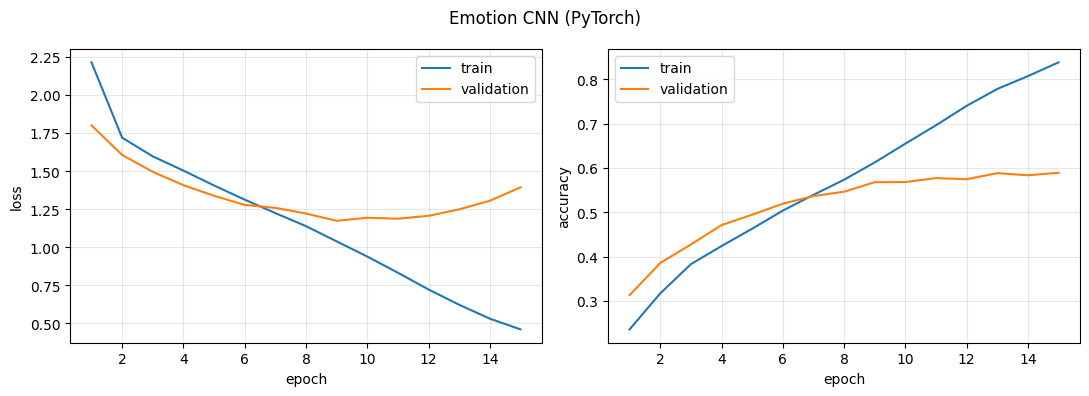

In [7]:
fig = plot_history(history, None if CHAY_THU else TEN, metric_label="accuracy",
                   title="Emotion CNN (PyTorch)")
plt.show()

# (4) Evaluate trained model

Kết quả gốc: `Test loss: 1.4070`, `Test accuracy: 0.5954`.

In [8]:
score = evaluate(model, test_loader, loss_fn, accuracy)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 1.3931563681099999
Test accuracy: 0.5890220117356393


In [9]:
if not CHAY_THU:
    save_history(history, TEN)
    save_metrics(TEN, test_loss=score[0], test_metric=score[1], n_params=n_params,
                 epochs_ran=len(history["loss"]), best_epoch=None, train_time_s=train_time,
                 device=device_name(device), seed=0)
    ghi_so_sanh(TEN, "2. CNN + MLP", "test_acc", keras=0.5954, pytorch=score[1],
                keras_params=19028287, pytorch_params=n_params, epochs_keras=15, epochs_pytorch=epochs,
                optimizer="Adam", lr=lr, batch=batch_size, device=device_name(device),
                train_time_s=train_time, seed=0,
                ghi_chu="Không chia 255 như gốc; test = PublicTest như gốc")

so_sanh.csv: 3_Emotion_Reg_CNN | test_acc Keras 0.5954 | PyTorch 0.5890 | chênh -0.0064


In [10]:
def get_emotion(ohv):
    """Như gốc: nhận vector (one-hot hoặc xác suất/logits) và trả tên cảm xúc theo argmax."""
    indx = int(np.argmax(np.asarray(ohv)))
    return ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral'][indx]

Keras gốc:
```python
img_indx = np.uint32(np.random.rand()*(testingset.shape[0] - 1))
sample = x_testing[img_indx, :]
sample = sample.reshape(48, 48)
pred_cls = model.predict(sample.reshape(1, 48, 48, 1))
```

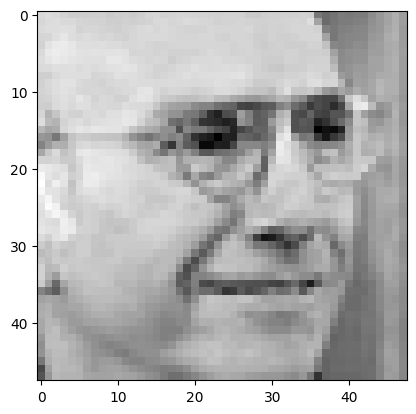

> testing image index: 1969
> true emotion: happy
> predicted emotion: angry


In [11]:
img_indx = np.uint32(np.random.rand() * (x_test.shape[0] - 1))
sample = x_test[img_indx]                          # (1, 48, 48)

pred_cls = predict(model, sample.unsqueeze(0))     # (1, 7) logits; argmax giống softmax

plt.imshow(sample[0], cmap='gray')
plt.show()
print('> testing image index: %d\n> true emotion: %s\n> predicted emotion: %s'
      % (img_indx, get_emotion(y_testing[img_indx, :]), get_emotion(pred_cls)))